### elimino modelli vecchi salvati in kaggle

In [ ]:
"""import shutil
import os

folder_path = '/kaggle/working/mymodel3'

if os.path.exists(folder_path) and os.path.isdir(folder_path):
    shutil.rmtree(folder_path)
    print(f"Cartella {folder_path} eliminata con tutto il suo contenuto.")
else:
    print("La cartella non esiste o non è una cartella.")"""


# Check dati


 ### check shape dataset

In [2]:
import os
import h5py

def validate_h5_dataset_shapes(base_dir, expected_rgb_shape=(3, 480, 640), expected_depth_shape=(480, 640)):
    invalid_files = []

    for root, _, files in os.walk(base_dir):
        for file in files:
            if not file.endswith('.h5'):
                continue

            full_path = os.path.join(root, file)
            try:
                with h5py.File(full_path, 'r') as f:
                    rgb = f['rgb']
                    depth = f['depth']

                    rgb_shape = rgb.shape
                    depth_shape = depth.shape

                    # Controllo rigoroso
                    valid_rgb = (rgb_shape == expected_rgb_shape)
                    valid_depth = (depth_shape == expected_depth_shape)

                    if not (valid_rgb and valid_depth):
                        invalid_files.append({
                            "file": full_path,
                            "rgb_shape": rgb_shape,
                            "depth_shape": depth_shape
                        })

            except Exception as e:
                invalid_files.append({
                    "file": full_path,
                    "error": str(e)
                })

    if invalid_files:
        print(f"\n⚠️ Trovati {len(invalid_files)} file con problemi (shape non corrispondenti esattamente):")
        for item in invalid_files:
            print(item)
    else:
        print("✅ Tutti i file hanno esattamente le dimensioni richieste.")

    return invalid_files




validate_h5_dataset_shapes("/kaggle/input/nyu-depth-v2/train")

✅ Tutti i file hanno esattamente le dimensioni richieste.


[]

### check elemento del dataset

Tipo RGB: uint8, bit per pixel RGB: 24
Tipo Depth: float32, bit per pixel Depth: 32
Dimensione immagine RGB: (3, 480, 640)
Dimensione immagine Depth: (480, 640)
Valori RGB (min, max): 1 255
Valori Depth (min, max, mean): 0.0 4.091099 2.3111475
Valori Depth validi (min, max): 1.2032644 4.091099


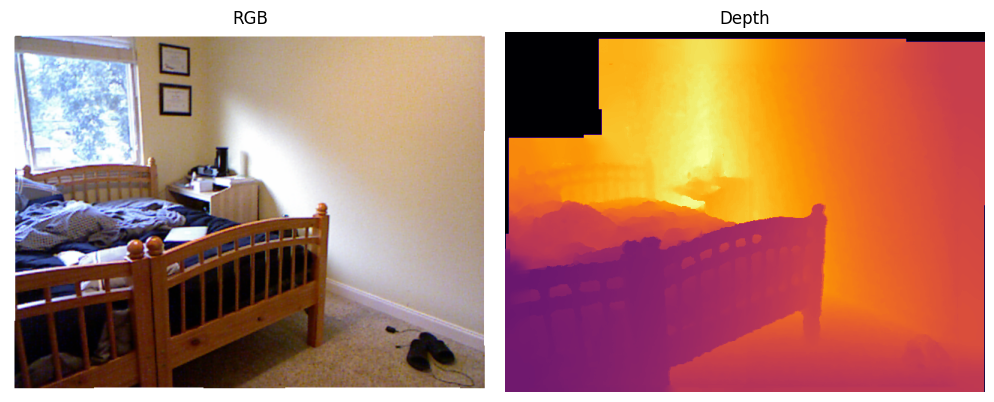

In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Carico un file .h5 a caso per ispezione
with h5py.File('/kaggle/input/nyu-depth-v2/train/bedroom_0074/00126.h5', 'r') as f:
    rgb = np.array(f['rgb'])     # (3, 480, 640)
    depth = np.array(f['depth']) # (480, 640)

    # Bit per pixel = bit per elemento * numero di canali (per RGB)
    rgb_dtype = rgb.dtype
    depth_dtype = depth.dtype

    bits_per_rgb_pixel = rgb_dtype.itemsize * 8 * rgb.shape[0]  # 3 canali
    bits_per_depth_pixel = depth_dtype.itemsize * 8

    print(f"Tipo RGB: {rgb_dtype}, bit per pixel RGB: {bits_per_rgb_pixel}")
    print(f"Tipo Depth: {depth_dtype}, bit per pixel Depth: {bits_per_depth_pixel}")

    # Controllo delle dimensioni
    print("Dimensione immagine RGB:", rgb.shape)
    print("Dimensione immagine Depth:", depth.shape)

    # Statistiche
    print("Valori RGB (min, max):", rgb.min(), rgb.max())
    print("Valori Depth (min, max, mean):", depth.min(), depth.max(), depth.mean())

    valid_depth = depth[depth > 0]
    print("Valori Depth validi (min, max):", valid_depth.min(), valid_depth.max())

    # Visualizzazione
    rgb_vis = np.transpose(rgb, (1, 2, 0))  # Da (3, 480, 640) a (480, 640, 3) 

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(rgb_vis.astype(np.uint8))
    plt.title("RGB")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(depth, cmap='inferno')
    plt.title("Depth")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


### check metodo inpainting

/tmp/ipykernel_77/1298355053.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  inferno_white = cm.get_cmap('inferno').copy()


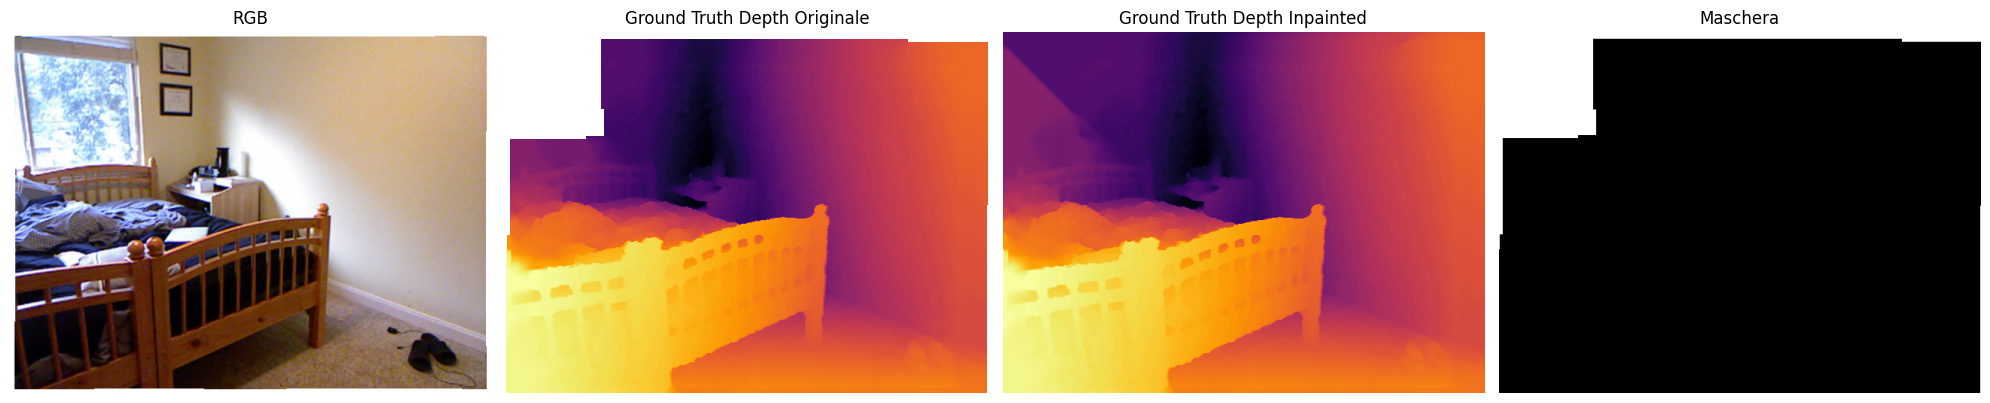

In [4]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cv2

def inpaint_depth_opencv(depth):
    valid_pixels = depth[depth > 0]
    if valid_pixels.size == 0:
        return depth.copy(), np.zeros_like(depth, dtype=np.uint8)

    depth_min = valid_pixels.min()
    depth_max = valid_pixels.max()

    mask = (depth < 1e-5).astype(np.uint8) * 255

    depth_norm = np.clip((depth - depth_min) / (depth_max - depth_min), 0, 1)
    inpainted_norm = cv2.inpaint(depth_norm.astype(np.float32), mask, inpaintRadius=3, flags=cv2.INPAINT_NS)
    inpainted = inpainted_norm * (depth_max - depth_min) + depth_min

    # Ripristina i valori originali dove non c'erano buchi
    inpainted[depth > 0] = depth[depth > 0]

    return inpainted, mask

# --- Caricamento dati ---
with h5py.File('/kaggle/input/nyu-depth-v2/train/bedroom_0074/00126.h5', 'r') as f:
    rgb = np.array(f['rgb'])     # (3, 480, 640)
    depth = np.array(f['depth']) # (480, 640)

    # RGB per visualizzazione
    rgb_vis = np.transpose(rgb, (1, 2, 0))

    # Maschera dei buchi (depth = 0)
    depth_masked = np.ma.masked_where(depth == 0, np.max(depth) - depth)

    # Colormap modificata per visualizzare i buchi come bianchi e gli oggetti lontani come scuri
    inferno_white = cm.get_cmap('inferno').copy()
    inferno_white.set_bad(color='white')

    inpainted_depth, mask = inpaint_depth_opencv(depth)
    inpainted_inverted = np.max(inpainted_depth) - inpainted_depth

    # --- Visualizzazione ---
    plt.figure(figsize=(20, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(rgb_vis.astype(np.uint8))
    plt.title("RGB")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(depth_masked, cmap=inferno_white)
    plt.title("Ground Truth Depth Originale")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(inpainted_inverted, cmap='inferno')
    plt.title("Ground Truth Depth Inpainted")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(mask, cmap='gray')
    plt.title("Maschera")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# Preparazione dei dati

### definizione parametri rete

In [5]:
batch_size     = 8
learning_rate  = 0.0001
epochs         = 15
subset_size    = 47000

### funzioni processamento dati

In [6]:
import h5py
import numpy as np
import tensorflow as tf
from sklearn.utils import shuffle
import cv2

def inpaint_depth_opencv(depth_np):
    """Inpainting con OpenCV dato un array depth (H, W)"""
    # Maschera: 1 dove mancano valori (0), 0 altrove
    mask = (depth_np <= 0).astype(np.uint8)

    # Normalizza per lavorare in float32 (range 0–1)
    d_min, d_max = np.min(depth_np[depth_np > 0]), np.max(depth_np)
    norm_depth = (depth_np - d_min) / (d_max - d_min)
    norm_depth = np.clip(norm_depth, 0, 1).astype(np.float32)

    # Inpaint usando Navier-Stokes (puoi cambiare flag)
    inpainted = cv2.inpaint(norm_depth, mask, inpaintRadius=3, flags=cv2.INPAINT_NS)

    # Ripristina scala originale
    restored = inpainted * (d_max - d_min) + d_min
    return restored.astype(np.float32)

def decode_and_preprocess_h5(h5_path_tensor,
                             rgb_shape=(480, 640, 3),
                             depth_shape=(240, 320, 1), 
                             downsample_depth=True):
    
    # Decodifica il path
    h5_path = h5_path_tensor.numpy().decode('utf-8')
    
    # Caricamento dati dal file .h5
    with h5py.File(h5_path, 'r') as f:
        rgb = f['rgb'][:]
        depth = f['depth'][:]
    
    # Gestione formato RGB [3, H, W] → [H, W, 3]
    rgb = np.transpose(rgb, (1, 2, 0))  # C, H, W → H, W, C

    # Inpainting con OpenCV 
    depth_inpainted = inpaint_depth_opencv(depth)
    
    # Espando immagine profondità [H, W] → [H, W, 1]
    depth = np.expand_dims(depth_inpainted, axis=-1)

    # Conversione in tensor
    rgb = tf.convert_to_tensor(rgb, dtype=tf.uint8)
    depth = tf.convert_to_tensor(depth, dtype=tf.float32)

    # Resize RGB 
    rgb = tf.image.resize(rgb, rgb_shape[:2], method='bilinear')

    # Resize immagine profondità
    if downsample_depth:
        depth = tf.image.resize(depth, depth_shape[:2], method='nearest')

    # Normalizzazione e trasformazione
    rgb = tf.cast(rgb, tf.float32) / 255.0
    depth = tf.cast(depth, tf.float32)
    depth_transformed = 10.0 / tf.clip_by_value(depth, 0.4, 10.0)

    return rgb, depth_transformed

def densedepth_augmentation(rgb, depth):
    # Flip orizzontale casuale (p=0.5)
    if tf.random.uniform([]) < 0.5:
        rgb = tf.image.flip_left_right(rgb)
        depth = tf.image.flip_left_right(depth)

    # Permutazione dei canali RGB (p=0.25)
    if tf.random.uniform([]) < 0.25:
        perms = tf.random.shuffle([0, 1, 2])
        rgb = tf.gather(rgb, perms, axis=-1)

    return rgb, depth

def create_nyu_dataset(base_dir, 
                       batch_size=8, 
                       shuffle_each_epoch=True, 
                       augment=True,
                       subset_size=None,
                       downsample_depth=True):
    
    # Lista file .h5
    h5_files = []
    for root, _, files in os.walk(base_dir):
        h5_files.extend([os.path.join(root, f) for f in files if f.endswith('.h5')])

    # Shuffle iniziale globale
    h5_files = shuffle(h5_files, random_state=42)

    # Subset se richiesto
    if subset_size:
        h5_files = h5_files[:subset_size]

    # Crea dataset da lista path
    ds = tf.data.Dataset.from_tensor_slices(h5_files)

    # Shuffle ad ogni epoca
    if shuffle_each_epoch:
        ds = ds.shuffle(len(h5_files), reshuffle_each_iteration=True)

    # pre-processing con py_function scorrendo il dataset
    def map_with_shape(x):
        
        rgb, depth = tf.py_function(
                func=lambda path:decode_and_preprocess_h5(path,downsample_depth=downsample_depth),
                inp=[x],
                Tout=[tf.float32, tf.float32])
        
        rgb = tf.ensure_shape(rgb, [480, 640, 3])
        if downsample_depth:
            depth = tf.ensure_shape(depth, [240, 320, 1])
        else:
            depth = tf.ensure_shape(depth, [480, 640, 1])
        return rgb, depth

    ds = ds.map(map_with_shape, num_parallel_calls=tf.data.AUTOTUNE)

    # augmentation
    if augment:
        ds = ds.map(densedepth_augmentation, num_parallel_calls=tf.data.AUTOTUNE)

    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

2025-06-12 10:39:48.010518: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749724788.213418      77 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749724788.277220      77 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


### creazione dataset

In [7]:
import os
train_table = create_nyu_dataset(
    base_dir="/kaggle/input/nyu-depth-v2/train",
    batch_size=batch_size,
    shuffle_each_epoch=True,
    augment=True,
    subset_size=subset_size,
    downsample_depth=True
)

display(train_table)

I0000 00:00:1749724849.827791      77 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1749724849.828537      77 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 480, 640, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 240, 320, 1), dtype=tf.float32, name=None))>

### check elemento train table creata

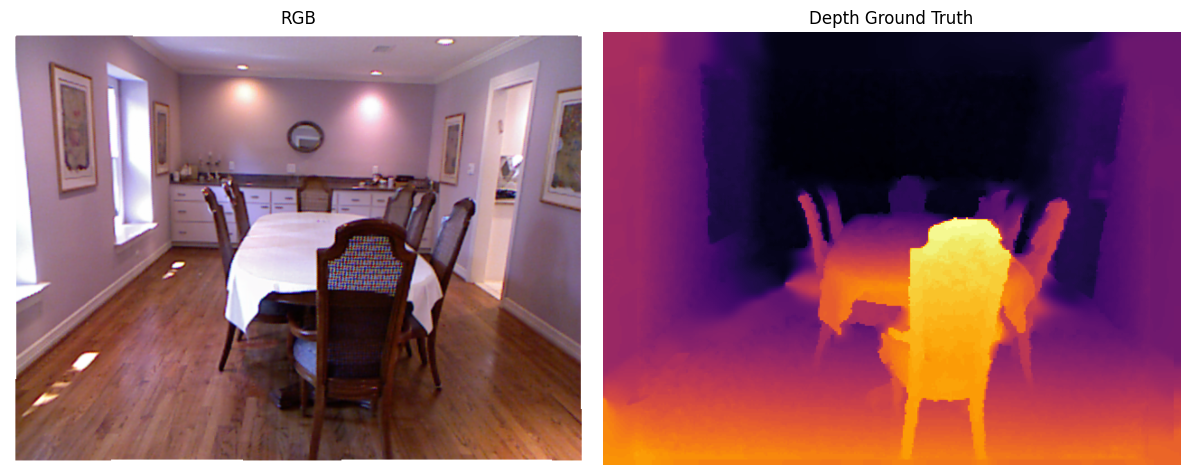

In [58]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

for batch in train_table.take(1):  # Prende solo un batch
    images, depths = batch

    rgb_sample = images[0].numpy()
    depth_transformed_sample = depths[0, :, :, 0].numpy()  # rimuove canale finale

    # Calcolo profondità originale invertendo la trasformazione
    #depth_original = 10.0 / depth_transformed_sample
    depth_original = depth_transformed_sample

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(rgb_sample)
    plt.title("RGB")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    # Visualizzo la profondità originale, normalizzata per mostrare meglio i valori
    depth_norm = (depth_original - depth_original.min()) / (depth_original.max() - depth_original.min())
    plt.imshow(depth_norm, cmap='inferno')
    plt.title("Depth Ground Truth")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Architettura

### Encoder

In [59]:
from tensorflow.keras.applications import DenseNet169
from tensorflow.keras.layers import Input

# Input layer
inputs = Input(shape=(480, 640, 3), name="input_image")

# Encoder
base_model = DenseNet169(include_top=False, weights='imagenet', input_tensor=inputs)

#base_model.summary()

# ultimo layer encoder
x = base_model.output # 15 × 20 × 1664

#Feature Map per le skip connections
pool3 = base_model.get_layer("pool3_pool").output # 30 × 40 × 256
pool2 = base_model.get_layer("pool2_pool").output # 60 × 80 × 128
pool1 = base_model.get_layer("pool1").output      # 120 × 160 × 64
conv1 = base_model.get_layer("conv1_relu").output # 240 × 320 × 64


51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### funzione blocco decoder

In [60]:
from tensorflow.keras.layers import UpSampling2D, Concatenate, Conv2D, LeakyReLU

def upscale_block(x, skip, filters, name):
    x = UpSampling2D(size=(2, 2), interpolation='bilinear', name=name + '_up')(x)

    x = Concatenate(name=name + '_concat')([x, skip])

    x = Conv2D(filters, 3, padding='same', name=name + '_convA')(x)
    x = LeakyReLU(negative_slope=0.2, name=name + '_actA')(x)

    x = Conv2D(filters, 3, padding='same', name=name + '_convB')(x)
    x = LeakyReLU(negative_slope=0.2, name=name + '_actB')(x)
    
    return x


### Decoder

In [61]:
# Conv 1×1 sull’output del blocco encoder 
x = Conv2D(filters=1664, kernel_size=1, padding='same', name='conv2')(x) #15 x 20 x 1664

#blocchi di upsampling + conc_skip + conv + conv
x = upscale_block(x, pool3, 832, 'up1') #30 x 40 x 832
x = upscale_block(x, pool2, 416, 'up2')  #60 x 80 x 416
x = upscale_block(x, pool1, 208, 'up3')  #120 x 160 x 208
x = upscale_block(x, conv1, 104, 'up4')  #240 x 320 x 104

# Output layer: : 1 canale
output = Conv2D(1, kernel_size=3, padding='same', name='depth')(x) # 240×320×1


### creazione effettiva dell'architettura

In [62]:
from tensorflow.keras.models import Model

model = Model(inputs=inputs, outputs=output)
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)  │ (None, 480, 640, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ zero_padding2d            │ (None, 486, 646, 3)    │              0 │ input_image[0][0]      │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_conv (Conv2D)       │ (None, 240, 320, 64)   │          9,408 │ zero_padding2d[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_bn                  │ (None, 240, 320, 64)   │            256 │ conv1_conv[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_relu (Activation)   │ (None, 240, 320, 64)   │              0 │ conv1_bn[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ zero_padding2d_1          │ (None, 242, 322, 64)   │              0 │ conv1_relu[0][0]       │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1 (MaxPooling2D)      │ (None, 120, 160, 64)   │              0 │ zero_padding2d_1[0][0] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_0_bn         │ (None, 120, 160, 64)   │            256 │ pool1[0][0]            │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_0_relu       │ (None, 120, 160, 64)   │              0 │ conv2_block1_0_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_conv       │ (None, 120, 160, 128)  │          8,192 │ conv2_block1_0_relu[0… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_bn         │ (None, 120, 160, 128)  │            512 │ conv2_block1_1_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_relu       │ (None, 120, 160, 128)  │              0 │ conv2_block1_1_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_conv       │ (None, 120, 160, 32)   │         36,864 │ conv2_block1_1_relu[0… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_concat       │ (None, 120, 160, 96)   │              0 │ pool1[0][0],           │
│ (Concatenate)             │                        │                │ conv2_block1_2_conv[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block2_0_bn    

 Total params: 42,816,089 (163.33 MB)

 Trainable params: 42,657,689 (162.73 MB)

 Non-trainable params: 158,400 (618.75 KB)

### definizione della loss

In [63]:
from tensorflow.keras import backend as K

def depth_loss_function(y_true, y_pred, theta=0.1, maxDepthVal = 10.0 / 0.4):
    
    # Point-wise depth
    l_depth = K.mean(K.abs(y_pred - y_true), axis=-1)

    # Edges
    dy_true, dx_true = tf.image.image_gradients(y_true)
    dy_pred, dx_pred = tf.image.image_gradients(y_pred)
    l_edges = K.mean(K.abs(dy_pred - dy_true) + K.abs(dx_pred - dx_true), axis=-1)

    # Structural similarity (SSIM) index
    l_ssim = K.clip((1 - tf.image.ssim(y_true, y_pred, maxDepthVal)) * 0.5, 0, 1)

    # Weights
    w1 = 1.0
    w2 = 1.0
    w3 = theta

    return (w1 * l_ssim) + (w2 * K.mean(l_edges)) + (w3 * K.mean(l_depth))

### compilo il modello, β1 e β2 sono 0.9 e 0.999 di default

In [64]:
import tensorflow

optimizer = tensorflow.keras.optimizers.Adam(learning_rate=learning_rate, amsgrad=True)

model.compile(loss=depth_loss_function, optimizer=optimizer)

### creazione di un file dove salvare il modello (pesi + ottimizzatore) ad ogni epoca

In [ ]:
import tensorflow
import os
checkpoint_path = "/kaggle/working/mymodel3/full_model_epoch_{epoch:02d}.keras"
checkpoint_dir = os.path.dirname(checkpoint_path)

os.makedirs(checkpoint_dir, exist_ok=True)

cp_callback = tensorflow.keras.callbacks.ModelCheckpoint(
                                                  filepath=checkpoint_path,
                                                  save_weights_only=False,
                                                  save_best_only=False,
                                                  verbose=1)

# Addestramento

### Addestro dalla prima epoca

In [ ]:
model.fit(train_table, epochs=epochs, callbacks=[cp_callback], verbose=True)



### Riprendo l'addestramento da un file .keras salvato

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/kaggle/working/mymodel3/full_model_epoch_14.keras",
                   custom_objects={"depth_loss_function": depth_loss_function})


# Continua fino alla 15ª
model.fit(train_table, initial_epoch=14, epochs=15, callbacks=[cp_callback])



# Test

### import librerie e definizioni

In [65]:
import os
import h5py
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from skimage.transform import resize

EIGEN_CROP = [45, 471, 41, 601]  # [top, bottom, left, right] per 480x640
modelfile = "/kaggle/input/modelli/full_model_epoch_14.keras"
test_dir = "/kaggle/input/nyu-depth-v2/val"

### creazione del test set

In [66]:
# dataset test
test_table = create_nyu_dataset(
    base_dir=test_dir,
    batch_size=batch_size,
    shuffle_each_epoch=False,  # No shuffle per evaluation
    augment=False,             # No augmentation per evaluation  
    subset_size=None,          # Usa tutto il test set
    downsample_depth=False      # Non devo fare il downsampling dell'immagine GT
)

### funzione di upsampling della predizione

In [67]:
def scale_up_2x(images):
    """
    Upsampling 2x usando interpolazione bilineare.
    Input: array di shape [batch, height, width, channels] o [batch, height, width]
    Output: array con dimensioni raddoppiate
    """
    scaled = []
    
    for i in range(len(images)):
        img = images[i]
        # Se l'immagine ha 3 dimensioni, rimuovi l'ultima se è 1
        if len(img.shape) == 3 and img.shape[-1] == 1:
            img = np.squeeze(img, axis=-1)
        
        # Calcola le nuove dimensioni (2x)
        output_shape = (img.shape[0] * 2, img.shape[1] * 2)
        
        # Usa resize con interpolazione bilineare
        scaled_img = resize(
            img, 
            output_shape, 
            order=1,  # Interpolazione bilineare
            preserve_range=True, 
            mode='reflect', 
            anti_aliasing=True
        )
        
        scaled.append(scaled_img)
    
    return np.stack(scaled)

### funzione che calcola output finale come media della predizione tra originale e specchiata

In [68]:
def predict_with_tta(model, rgb_batch):
    """
    Predizione con Test Time Augmentation (TTA) usando mirror image.
    
    Args:
        model: modello Keras addestrato
        rgb_batch: batch di immagini RGB [batch_size, 480, 640, 3]
    
    Returns:
        predictions: predizioni medie con TTA [batch_size, 480, 640]
    """
    
    # Predizione normale
    pred_normal = model.predict(rgb_batch, verbose=0)  # [batch, 240, 320, 1]
    
    # Predizione della mirror image (flip orizzontale)
    rgb_flipped = tf.reverse(rgb_batch, axis=[2])  # Flip lungo l'asse width
    pred_flipped = model.predict(rgb_flipped, verbose=0)  # [batch, 240, 320, 1]
    
    # Converti in numpy e rimuove l'ultima dimensione 
    pred_normal = np.squeeze(pred_normal, axis=-1)  # [batch, 240, 320]
    pred_flipped = np.squeeze(pred_flipped, axis=-1)  # [batch, 240, 320]
    
    # Upsampling 2x per entrambe le predizioni
    pred_normal_upsampled = scale_up_2x(pred_normal)  # [batch, 480, 640]
    pred_flipped_upsampled = scale_up_2x(pred_flipped)  # [batch, 480, 640]
    
    # Flip back della predizione flippata
    pred_flipped_back = np.flip(pred_flipped_upsampled, axis=2)  # [batch, 480, 640]
    
    # Media delle due predizioni (TTA)
    final_predictions = 0.5 * pred_normal_upsampled + 0.5 * pred_flipped_back
    
    return final_predictions

### funzione per il calcolo delle metriche quantitative

In [69]:
def compute_depth_metrics(gt, pred):
    """
    Calcola le metriche standard per depth estimation secondo Eigen et al.
    
    Args:
        gt: ground truth depth map
        pred: predicted depth map
    
    Returns:
        tuple: (a1, a2, a3, abs_rel, rmse, log_10)
    """
    # Evita valori invalidi
    mask = (gt > 0) & (pred > 0) & (~np.isnan(gt)) & (~np.isnan(pred))
    gt_valid = gt[mask]
    pred_valid = pred[mask]
    
    if len(gt_valid) == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan
    
    # Calcolo delle soglie per accuracy metrics
    thresh = np.maximum((gt_valid / pred_valid), (pred_valid / gt_valid))
    
    # Accuracy metrics
    a1 = (thresh < 1.25).mean()
    a2 = (thresh < 1.25 ** 2).mean()
    a3 = (thresh < 1.25 ** 3).mean()
    
    # Error metrics
    abs_rel = np.mean(np.abs(gt_valid - pred_valid) / gt_valid)
    
    rmse = np.sqrt(np.mean((gt_valid - pred_valid) ** 2))
    
    log_10 = np.mean(np.abs(np.log10(gt_valid) - np.log10(pred_valid)))
    
    return a1, a2, a3, abs_rel, rmse, log_10

### funzione di visualizzazione 

In [77]:
def visualize_prediction(rgb, gt_depth, pred_depth, sample_index=0, vmax=10.0):
    """
    Visualizza RGB, GT depth e predizione per un dato sample.
    
    Args:
        rgb: batch di immagini RGB [B, 480, 640, 3]
        gt_depth: batch di ground truth depth maps [B, 480, 640]
        pred_depth: batch di mappe di profondità predette [B, 480, 640]
        sample_index: indice del sample da visualizzare
        vmax: valore massimo per la visualizzazione della profondità
    """
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))
    
    rgb_sample = rgb[sample_index]
    gt_sample = gt_depth[sample_index]
    pred_sample = pred_depth[sample_index]

    # Calcolo range comune da usare per normalizzare entrambe (per confronto visivo)
    depth_min = min(gt_sample.min(), pred_sample.min())
    depth_max = max(gt_sample.max(), pred_sample.max())

    gt_sample_vis = 10 * (gt_sample - depth_min) / (depth_max - depth_min)
    pred_sample_vis = 10 * (pred_sample - depth_min) / (depth_max - depth_min)


    axs[0].imshow(rgb_sample.astype('float32'))
    axs[0].set_title("RGB Image")
    axs[0].axis('off')

    im1 = axs[1].imshow(gt_sample_vis, cmap='plasma', vmin=0.0, vmax=vmax)
    axs[1].set_title("Ground Truth Depth")
    axs[1].axis('off')
    fig.colorbar(im1, ax=axs[1])
    
    im2 = axs[2].imshow(pred_sample_vis, cmap='plasma')
    axs[2].set_title("Predicted Depth")
    axs[2].axis('off')
    fig.colorbar(im2, ax=axs[2])

    plt.tight_layout()
    plt.show()

### funzione di valutazione

In [78]:
def evaluate_model_complete(model, test_dataset, max_batches=None):
    """
    Valutazione completa del modello su tutto il test set.
    
    Args:
        model: modello Keras addestrato
        test_dataset: dataset di test
        max_batches: limite massimo di batch da processare (None = tutti)
    
    Returns:
        metr: metriche medie su tutto il dataset
    """
    print("Iniziando valutazione completa del modello...")
    print("Implementando TTA (Test Time Augmentation) e upsampling 2x")
    print(f"Crop di Eigen et al.: {EIGEN_CROP}")
    print("-" * 60)
    
    # Accumulatori per le metriche
    all_metrics = []
    
    total_samples = 0
    batch_count = 0
    
    for batch_idx, (rgb_batch, depth_batch) in enumerate(test_dataset):
        if max_batches is not None and batch_idx >= max_batches:
            break
            
        batch_count += 1
        current_batch_size = rgb_batch.shape[0]
        total_samples += current_batch_size
        
        print(f"Processando batch {batch_count}, samples: {current_batch_size}")
        
        # Predizione con TTA
        predictions = predict_with_tta(model, rgb_batch)  # ritorna [batch, 480, 640]
        
        # Processamento ground truth
        depth_batch_np = depth_batch.numpy()  # [batch, 480, 640, 1]
        depth_batch_squeezed = np.squeeze(depth_batch_np, axis=-1)  # [batch, 480, 640]

        gt_original = depth_batch_squeezed
        pred_original = predictions
        
        # Applicazione del crop di Eigen et al.
        crop = EIGEN_CROP
        gt_cropped = gt_original[:, crop[0]:crop[1]+1, crop[2]:crop[3]+1]
        pred_cropped = pred_original[:, crop[0]:crop[1]+1, crop[2]:crop[3]+1]
        
        # Calcolo metriche per ogni sample nel batch
        for i in range(current_batch_size):

            # Metriche quantitative
            metrics = compute_depth_metrics(gt_cropped[i], pred_cropped[i])

            if batch_idx == 2 and i == 3:
                visualize_prediction(rgb_batch.numpy(), gt_original, pred_original, sample_index=i)

            all_metrics.append(metrics)
    
    # Calcolo delle metriche medie
    all_metrics = np.array(all_metrics)
    
    # Rimuovi eventuali NaN
    valid_mask = ~np.isnan(all_metrics).any(axis=1)
    all_metrics_valid = all_metrics[valid_mask]
    
    if len(all_metrics_valid) == 0:
        print("ERRORE: Nessuna metrica valida calcolata!")
        return None
    
    mean_metrics = np.mean(all_metrics_valid, axis=0)

    
    # Risultati
    results = {
        'a1': mean_metrics[0],
        'a2': mean_metrics[1], 
        'a3': mean_metrics[2],
        'abs_rel': mean_metrics[3],
        'rmse': mean_metrics[4],
        'log_10': mean_metrics[5],
        'total_samples': total_samples,
        'valid_samples': len(all_metrics_valid)
    }
    
    return results

### carico e valuto il modello

Modello caricato da: /kaggle/input/modelli/full_model_epoch_14.keras

Iniziando valutazione completa del modello...
Implementando TTA (Test Time Augmentation) e upsampling 2x
Crop di Eigen et al.: [45, 471, 41, 601]
------------------------------------------------------------
Processando batch 1, samples: 8
Processando batch 2, samples: 8
Processando batch 3, samples: 8


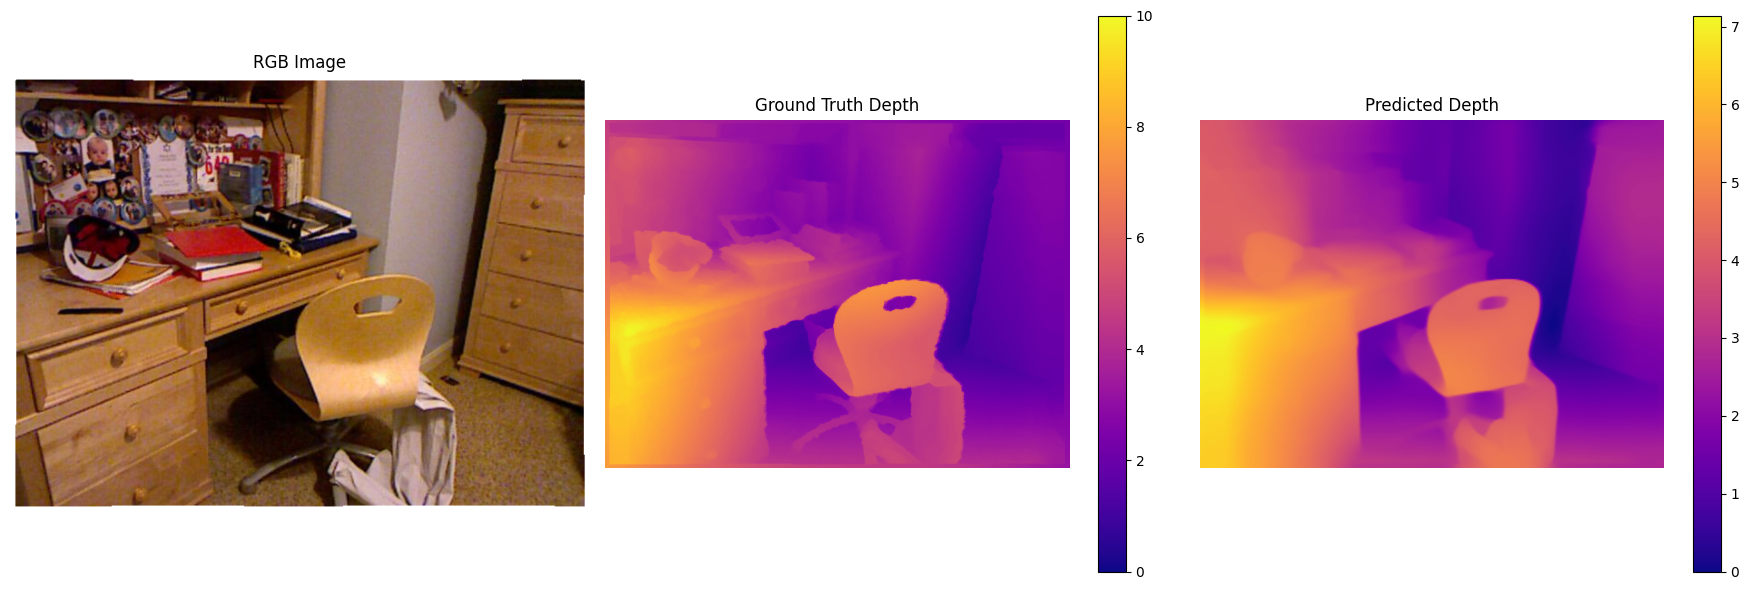

Processando batch 4, samples: 8
Processando batch 5, samples: 8
Processando batch 6, samples: 8
Processando batch 7, samples: 8
Processando batch 8, samples: 8
Processando batch 9, samples: 8
Processando batch 10, samples: 8
Processando batch 11, samples: 8
Processando batch 12, samples: 8
Processando batch 13, samples: 8
Processando batch 14, samples: 8
Processando batch 15, samples: 8
Processando batch 16, samples: 8
Processando batch 17, samples: 8
Processando batch 18, samples: 8
Processando batch 19, samples: 8
Processando batch 20, samples: 8
Processando batch 21, samples: 8
Processando batch 22, samples: 8
Processando batch 23, samples: 8
Processando batch 24, samples: 8
Processando batch 25, samples: 8
Processando batch 26, samples: 8
Processando batch 27, samples: 8
Processando batch 28, samples: 8
Processando batch 29, samples: 8
Processando batch 30, samples: 8
Processando batch 31, samples: 8
Processando batch 32, samples: 8
Processando batch 33, samples: 8
Processando batc

In [79]:
# Carico il modello salvato
model = tf.keras.models.load_model(modelfile, custom_objects={'depth_loss_function': depth_loss_function})
print(f"Modello caricato da: {modelfile}\n")

# Valutazione 
# N.B. max_batches=None per processare tutto il dataset
results = evaluate_model_complete(model, test_table, max_batches=None)

### stampa dei risultati

In [80]:
def print_results(results):
    """Stampa i risultati in formato completo"""
    if results is None:
        print("Nessun risultato da mostrare")
        return
        
    print("\n" + "="*70)
    print("RISULTATI VALUTAZIONE DEPTH ESTIMATION")
    print("="*70)
    print(f"Samples totali processati: {results['total_samples']}")
    print(f"Samples validi per metriche: {results['valid_samples']}")
    print("-"*70)
    
    # Metriche quantitative
    print("Metriche Quantitative:")
    print("{:>10}, {:>10}, {:>10}, {:>10}, {:>10}, {:>10}".format(
        'a1', 'a2', 'a3', 'abs_rel', 'rmse', 'log_10'))
    print("{:10.4f}, {:10.4f}, {:10.4f}, {:10.4f}, {:10.4f}, {:10.4f}".format(
        results['a1'], results['a2'], results['a3'], 
        results['abs_rel'], results['rmse'], results['log_10']))
    
    print("-"*70)



print_results(results)


RISULTATI VALUTAZIONE DEPTH ESTIMATION
Samples totali processati: 654
Samples validi per metriche: 654
----------------------------------------------------------------------
Metriche Quantitative:
        a1,         a2,         a3,    abs_rel,       rmse,     log_10
    0.8491,     0.9713,     0.9937,     0.1268,     0.8078,     0.0533
----------------------------------------------------------------------


# Prova

In [84]:
import numpy as np
from skimage.transform import resize
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import os
import tensorflow as tf

# Preprocessa l'immagine dal dataset
def preprocess_image_from_dataset(dataset_path, image_filename, target_shape=(480, 640, 3)):
    img_path = os.path.join(dataset_path, image_filename)
    
    if not os.path.exists(img_path):
        print(f"❌ File non trovato: {img_path}")
        try:
            for f in os.listdir(dataset_path):
                print(f"   - {f}")
        except:
            print("   Impossibile leggere il contenuto del dataset")
        return None, None, None

    
    original_img = Image.open(img_path)
    original_array = np.array(original_img)
    
    target_height, target_width = target_shape[:2]
    img_resized = cv2.resize(original_array, (target_width, target_height))
    
    img_normalized = img_resized.astype(np.float32) / 255.0
    img_batch = np.expand_dims(img_normalized, axis=0)
    
    return img_batch, img_resized, original_array

#  Esegue la predizione con TTA
def predict_depth_with_tta(model, img_batch):
    depth_predictions = predict_with_tta(model, img_batch)
    depth_map = depth_predictions[0]
    return depth_map

# Visualizza i risultati 
def visualize_results(resized_img, depth_map):
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
    # Immagine ridimensionata
    axes[0].imshow(resized_img)
    axes[0].set_title(f'Ridimensionata\n{resized_img.shape[1]}×{resized_img.shape[0]}', fontsize=12)
    axes[0].axis('off')

    depth_map_vis = 10 * (depth_map - depth_map.min()) / (depth_map.max() - depth_map.min())
    
    im2 = axes[1].imshow(depth_map, cmap='plasma')
    axes[1].set_title(f'Depth Map\n{depth_map.shape[1]}×{depth_map.shape[0]}', fontsize=12)
    axes[1].axis('off')
    plt.colorbar(im2, ax=axes[1], shrink=0.8)
    
    plt.tight_layout()
    plt.show()


# FUNZIONE PRINCIPALE
def run_depth_prediction_from_dataset(model, dataset_path, image_filename):
    
    img_batch, img_display, original_img = preprocess_image_from_dataset(
        dataset_path, image_filename
    )
    
    if img_batch is None:
        return None
    
    depth_map = predict_depth_with_tta(model, img_batch)
    
    visualize_results(img_display, depth_map)
    
    return depth_map


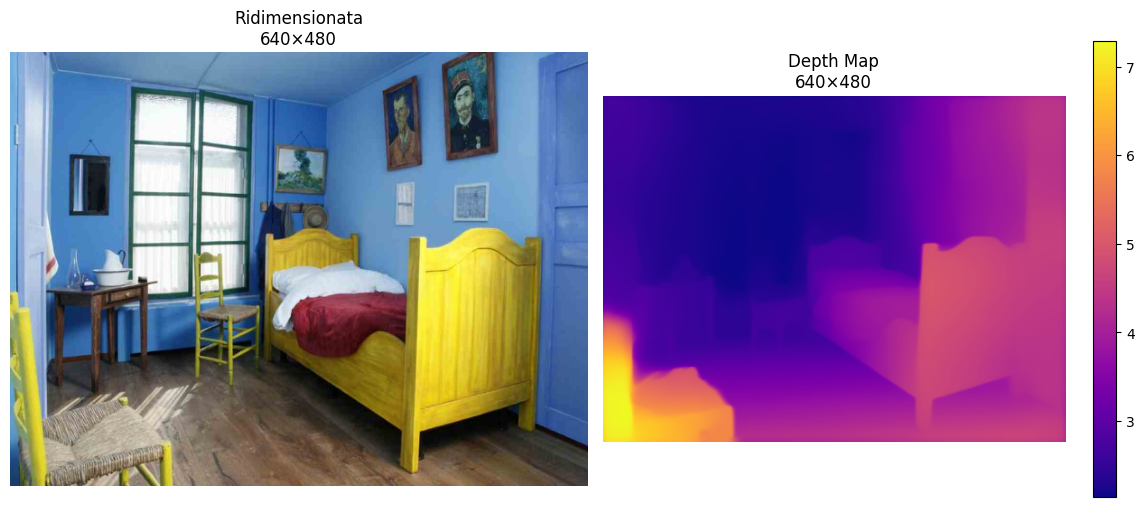

In [97]:
modelfile = "/kaggle/input/modelli/full_model_epoch_14.keras"
# Carico il modello salvato
model = tf.keras.models.load_model(modelfile, custom_objects={'depth_loss_function': depth_loss_function})

# Configura i path
dataset_path = "/kaggle/input/foto-modello"  # nome del tuo dataset
image_filename = "Van_Gogh.jpg"  # nome del tuo file JPG

depth_map = run_depth_prediction_from_dataset(
    model=model, 
    dataset_path=dataset_path, 
    image_filename=image_filename
)